In [70]:
import numpy as np
import pandas as pd

In [71]:
df = pd.read_csv("Churn_Modelling.csv")

In [72]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [73]:
df.shape

(10000, 14)

In [74]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [75]:
df.duplicated().sum()

np.int64(0)

In [76]:
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [77]:
df['Geography'].value_counts()
df['Geography'].unique()

array(['France', 'Spain', 'Germany'], dtype=object)

In [78]:
df['Gender'].value_counts()

Gender
Male      5457
Female    4543
Name: count, dtype: int64

In [79]:
df.drop(columns = ['RowNumber', 'CustomerId', 'Surname'], inplace = True)

In [80]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [81]:
df = pd.get_dummies(df, columns = ['Geography', 'Gender'], drop_first = True , dtype = int)

In [82]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CreditScore        10000 non-null  int64  
 1   Age                10000 non-null  int64  
 2   Tenure             10000 non-null  int64  
 3   Balance            10000 non-null  float64
 4   NumOfProducts      10000 non-null  int64  
 5   HasCrCard          10000 non-null  int64  
 6   IsActiveMember     10000 non-null  int64  
 7   EstimatedSalary    10000 non-null  float64
 8   Exited             10000 non-null  int64  
 9   Geography_Germany  10000 non-null  int64  
 10  Geography_Spain    10000 non-null  int64  
 11  Gender_Male        10000 non-null  int64  
dtypes: float64(2), int64(10)
memory usage: 937.6 KB


In [83]:
X = df.drop(columns=['Exited'])
y = df['Exited']
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = 1)

In [84]:
y

0       1
1       0
2       1
3       0
4       0
       ..
9995    0
9996    0
9997    1
9998    1
9999    0
Name: Exited, Length: 10000, dtype: int64

In [85]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [86]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

In [99]:
model = Sequential()
model.add(Dense(11, activation='relu', input_dim = 11))
model.add(Dense(11, activation='relu'))
model.add(Dense(1,activation='sigmoid'))


In [100]:
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                 │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            12 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 276 (1.08 KB)

 Trainable params: 276 (1.08 KB)

 Non-trainable params: 0 (0.00 B)

In [101]:
model.compile(loss = 'binary_crossentropy', optimizer = 'Adam', metrics=['accuracy'])

In [107]:
history = model.fit(X_train_scaled, y_train, epochs = 10, validation_split = 0.2)

Epoch 1/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8531 - loss: 0.3604 - val_accuracy: 0.8481 - val_loss: 0.3661
Epoch 2/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8533 - loss: 0.3571 - val_accuracy: 0.8537 - val_loss: 0.3603
Epoch 3/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 916us/step - accuracy: 0.8572 - loss: 0.3534 - val_accuracy: 0.8550 - val_loss: 0.3588
Epoch 4/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 894us/step - accuracy: 0.8578 - loss: 0.3502 - val_accuracy: 0.8575 - val_loss: 0.3566
Epoch 5/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 929us/step - accuracy: 0.8578 - loss: 0.3479 - val_accuracy: 0.8550 - val_loss: 0.3565
Epoch 6/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 908us/step - accuracy: 0.8598 - loss: 0.3461 - val_accuracy: 0.8575 - val_loss: 0.3546
Epoch 7/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 896us/step - accuracy: 0.8600 - loss: 0.3446 - val_accuracy: 0.8575 - val_loss: 0.3544
Epoch 8/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 904us/step - accuracy: 0.8622 - loss: 0.3435 - val_

In [103]:
model.layers[0].get_weights()

[array([[ 1.19493224e-01,  2.00101882e-01,  1.64016321e-01,
          1.00355968e-01,  2.12723568e-01,  8.00462514e-02,
          9.80785340e-02, -4.41527031e-02,  2.66211063e-01,
          5.45135252e-02,  7.41751492e-02],
        [-8.40997994e-01,  4.10979055e-03, -4.28908467e-01,
          7.27378666e-01,  7.68999532e-02, -4.98008847e-01,
          1.87745810e-01,  3.98111403e-01, -2.88615096e-02,
         -7.39513695e-01, -6.26885712e-01],
        [-2.63203233e-01, -1.73400849e-01,  4.80094925e-02,
          3.03610057e-01, -6.57943115e-02,  3.31502020e-01,
         -8.74351114e-02,  1.28788903e-01, -2.24093899e-01,
          2.52737850e-01, -2.21506029e-01],
        [ 5.25546849e-01, -5.39097846e-01, -2.04566750e-03,
          5.10275215e-02, -2.45005235e-01, -4.81047750e-01,
          5.94127893e-01, -2.00109735e-01, -3.70223045e-01,
         -4.95031297e-01,  5.66491306e-01],
        [-6.89193234e-02, -2.02435926e-02, -1.22681417e-01,
         -3.15423042e-01, -1.04241884e+00,  

In [104]:
y_log = model.predict(X_test_scaled)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [105]:
y_pred = np.where(y_log>0.5,1,0)

In [106]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.853

In [108]:
import matplotlib.pyplot as plt

In [109]:
history.history

{'accuracy': [0.8531249761581421,
  0.8532812595367432,
  0.8571875095367432,
  0.8578125238418579,
  0.8578125238418579,
  0.8598437309265137,
  0.8600000143051147,
  0.8621875047683716,
  0.8598437309265137,
  0.8631250262260437],
 'loss': [0.36039748787879944,
  0.3570767343044281,
  0.3533977270126343,
  0.35021907091140747,
  0.3479185402393341,
  0.34605708718299866,
  0.3446267247200012,
  0.34352606534957886,
  0.34187325835227966,
  0.3415021002292633],
 'val_accuracy': [0.8481249809265137,
  0.8537499904632568,
  0.8550000190734863,
  0.8575000166893005,
  0.8550000190734863,
  0.8575000166893005,
  0.8575000166893005,
  0.8575000166893005,
  0.8518750071525574,
  0.8550000190734863],
 'val_loss': [0.366145521402359,
  0.36027786135673523,
  0.3588491380214691,
  0.35658225417137146,
  0.35646289587020874,
  0.3545606732368469,
  0.3544129431247711,
  0.3533332049846649,
  0.35535693168640137,
  0.3512553870677948]}

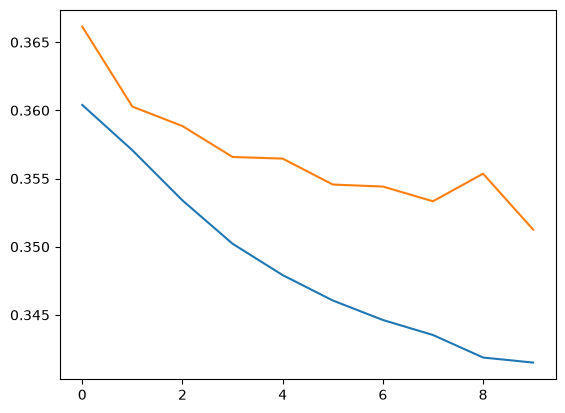

In [112]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

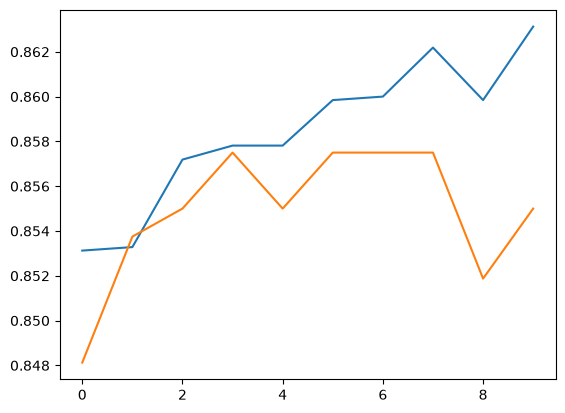

In [113]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])